# **Data Science and Machine Learning 1 - Year 4 Portfolio**
## Last.fm Decision Tree
*By Mark Lambert - C00192497 | [LinkedIn](https://www.linkedin.com/in/mark-lambert-27tw721921/) | [GitHub](https://github.com/lambert-27)* | [Personal Email](mailto:marklambert123@gmail.com)

*Lecturer: Ben O'Shaughnessey*

*Submission Date: 27th November 2026*

*Start Date: 9th November 2026*

---

## Research question



In [16]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns; sns.set()
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import BaggingClassifier, RandomForestClassifier, RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

audio = ['danceability', 'energy', 'loudness', 'speechiness', 'acousticness',
         'instrumentalness', 'liveness', 'valence', 'tempo', 'duration']

plays = pd.read_csv('../datasets/scrobbles.csv')
tracks = pd.read_csv('../datasets/scrobbled_merged_with_hugging_face.csv')

# one row per track
tracks = tracks.dropna(subset=['track_id'] + audio).drop_duplicates(subset='track_id')
print(len(tracks))

1838


Making a Decision Tree to predict the top four artists based on two features, `energy` and `acousticness`

['Portishead', 'Arctic Monkeys', 'Tame Impala', 'Red Hot Chili Peppers']


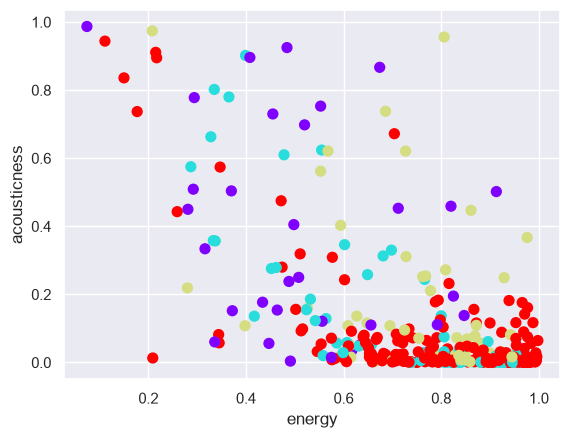

In [19]:
top4 = plays['artist'].value_counts().head(4).index
sub4 = tracks[tracks['artist'].isin(top4)]

X2 = sub4[['energy', 'acousticness']].values
y2, names4 = pd.factorize(sub4['artist'])

plt.scatter(X2[:, 0], X2[:, 1], c=y2, s=50, cmap='rainbow')
plt.xlabel('energy')
plt.ylabel('acousticness')
print(list(names4))

Using the example [handbook](https://github.com/jakevdp/PythonDataScienceHandbook/blob/master/notebooks/05.08-Random-Forests.ipynb), I have pulled the `visuaalise_classsifier()` function

In [3]:
# visualization helper from the Handbook
def visualise_classifier(model, X, y, ax=None, cmap='rainbow'):
    ax = ax or plt.gca()

    # Plot the training points
    ax.scatter(X[:, 0], X[:, 1], c=y, s=30, cmap=cmap,
               clim=(y.min(), y.max()), zorder=3)
    ax.axis('tight')
    ax.axis('off')
    xlim = ax.get_xlim()
    ylim = ax.get_ylim()

    # fit the estimator
    model.fit(X, y)
    xx, yy = np.meshgrid(np.linspace(*xlim, num=200),
                         np.linspace(*ylim, num=200))
    Z = model.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)

    # Create a color plot with the results
    n_classes = len(np.unique(y))
    contours = ax.contourf(xx, yy, Z, alpha=0.3,
                           levels=np.arange(n_classes + 1) - 0.5,
                           cmap=cmap, zorder=1)

    ax.set(xlim=xlim, ylim=ylim)

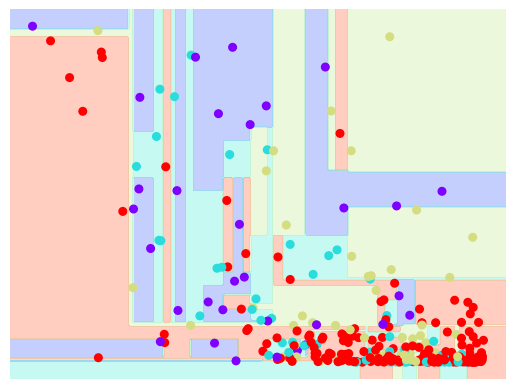

In [4]:
tree = DecisionTreeClassifier(random_state=0)
visualise_classifier(tree, X2, y2)